In [146]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [147]:
REUTERS_TRAIN_DIR = "/content/drive/MyDrive/nlp_midterm/reuters/train.csv"
REUTERS_TEST_DIR =  "/content/drive/MyDrive/nlp_midterm/reuters/test.csv"
Spooky_Aurthor_DIR = "/content/drive/MyDrive/nlp_midterm/Spooky_Author /Spooky_Author_Dataset.csv"

In [148]:
import os
import re
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import wordnet
import spacy
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [149]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [150]:
df1 = pd.read_csv(REUTERS_TRAIN_DIR, encoding ='unicode_escape')
df2 = pd.read_csv(REUTERS_TEST_DIR, encoding ='unicode_escape')


train_data1 = df1[["text", "author"]]
train_data1.dropna(how='any', inplace=True)
print(train_data1.head())

test_data1 = df2[["text", "author"]]
test_data1.dropna(how='any', inplace=True)
print(test_data1.head())



                                                text         author
0  The Internet continued to grow in leaps and bo...  AaronPressman
1  Elementary school students with access to the ...  AaronPressman
2  Hewlett-Packard Co. unveiled a new plan Monday...  AaronPressman
3  A U.S. District Court judge Wednesday barred n...  AaronPressman
4  With the Clinton administration busily reworki...  AaronPressman
                                                text         author
0  U.S. lawmakers redrafting a legislative propos...  AaronPressman
1  On the Internet, where new products come and g...  AaronPressman
2  U.S. Senators on Tuesday sharply criticized a ...  AaronPressman
3  Senator Bob Kerrey is preparing legislation in...  AaronPressman
4  The largest online services providers reacted ...  AaronPressman


/tmp/ipykernel_856/1313895593.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data1.dropna(how='any', inplace=True)
/tmp/ipykernel_856/1313895593.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data1.dropna(how='any', inplace=True)


In [151]:
train_data1["tokens"] = train_data1["text"].apply(word_tokenize)
print(train_data1[["text", "tokens"]].head())


test_data1["tokens"] = test_data1["text"].apply(word_tokenize)
print(test_data1[["text", "tokens"]].head())

                                                text  \
0  The Internet continued to grow in leaps and bo...   
1  Elementary school students with access to the ...   
2  Hewlett-Packard Co. unveiled a new plan Monday...   
3  A U.S. District Court judge Wednesday barred n...   
4  With the Clinton administration busily reworki...   

                                              tokens  
0  [The, Internet, continued, to, grow, in, leaps...  
1  [Elementary, school, students, with, access, t...  
2  [Hewlett-Packard, Co., unveiled, a, new, plan,...  
3  [A, U.S., District, Court, judge, Wednesday, b...  
4  [With, the, Clinton, administration, busily, r...  
                                                text  \
0  U.S. lawmakers redrafting a legislative propos...   
1  On the Internet, where new products come and g...   
2  U.S. Senators on Tuesday sharply criticized a ...   
3  Senator Bob Kerrey is preparing legislation in...   
4  The largest online services providers reacted ... 

In [152]:
train_data1["tokens"] = [
    [word.lower() for word in words]
    for words in train_data1["tokens"]
]
print(train_data1["tokens"].head())


test_data1["tokens"] = [
    [word.lower() for word in words]
    for words in test_data1["tokens"]
]
print(test_data1["tokens"].head())

0    [the, internet, continued, to, grow, in, leaps...
1    [elementary, school, students, with, access, t...
2    [hewlett-packard, co., unveiled, a, new, plan,...
3    [a, u.s., district, court, judge, wednesday, b...
4    [with, the, clinton, administration, busily, r...
Name: tokens, dtype: object
0    [u.s., lawmakers, redrafting, a, legislative, ...
1    [on, the, internet, ,, where, new, products, c...
2    [u.s, ., senators, on, tuesday, sharply, criti...
3    [senator, bob, kerrey, is, preparing, legislat...
4    [the, largest, online, services, providers, re...
Name: tokens, dtype: object


In [153]:

nlp = spacy.load("en_core_web_sm")

In [154]:

train_data1["tokens"] = train_data1["tokens"].apply(
    lambda words: [token.lemma_ for token in nlp(" ".join(words))]
)

print(train_data1["tokens"].head())




test_data1["tokens"] = test_data1["tokens"].apply(
    lambda words: [token.lemma_ for token in nlp(" ".join(words))]
)

print(test_data1["tokens"].head())

0    [the, internet, continue, to, grow, in, leap, ...
1    [elementary, school, student, with, access, to...
2    [hewlett, -, packard, co., unveil, a, new, pla...
3    [a, u.s, ., district, court, judge, wednesday,...
4    [with, the, clinton, administration, busily, r...
Name: tokens, dtype: object
0    [u.s, ., lawmaker, redrafte, a, legislative, p...
1    [on, the, internet, ,, where, new, product, co...
2    [u.s, ., senator, on, tuesday, sharply, critic...
3    [senator, bob, kerrey, be, prepare, legislatio...
4    [the, large, online, service, provider, react,...
Name: tokens, dtype: object


In [155]:
stop_words = set(stopwords.words("english"))


In [156]:

train_data1["tokens"] = train_data1["tokens"].apply(
    lambda words: [word for word in words if word not in stop_words]
)

print(train_data1["tokens"].head())




test_data1["tokens"] = test_data1["tokens"].apply(
    lambda words: [word for word in words if word not in stop_words]
)

print(test_data1["tokens"].head())

0    [internet, continue, grow, leap, bound, year, ...
1    [elementary, school, student, access, internet...
2    [hewlett, -, packard, co., unveil, new, plan, ...
3    [u.s, ., district, court, judge, wednesday, ba...
4    [clinton, administration, busily, rework, 1995...
Name: tokens, dtype: object
0    [u.s, ., lawmaker, redrafte, legislative, prop...
1    [internet, ,, new, product, come, go, blink, e...
2    [u.s, ., senator, tuesday, sharply, criticize,...
3    [senator, bob, kerrey, prepare, legislation, a...
4    [large, online, service, provider, react, caut...
Name: tokens, dtype: object


In [157]:
train_data1["tokens"] = train_data1["tokens"].apply(
    lambda words: [word for word in words if word not in string.punctuation]
)

print(train_data1["tokens"].head())

test_data1["tokens"] = test_data1["tokens"].apply(
    lambda words: [word for word in words if word not in string.punctuation]
)

print(test_data1["tokens"].head())

0    [internet, continue, grow, leap, bound, year, ...
1    [elementary, school, student, access, internet...
2    [hewlett, packard, co., unveil, new, plan, mon...
3    [u.s, district, court, judge, wednesday, bar, ...
4    [clinton, administration, busily, rework, 1995...
Name: tokens, dtype: object
0    [u.s, lawmaker, redrafte, legislative, proposa...
1    [internet, new, product, come, go, blink, eye,...
2    [u.s, senator, tuesday, sharply, criticize, ne...
3    [senator, bob, kerrey, prepare, legislation, a...
4    [large, online, service, provider, react, caut...
Name: tokens, dtype: object


In [158]:
train_data1["processed_text"] = train_data1["tokens"].apply(" ".join)

train_data1.head()




test_data1["processed_text"] = test_data1["tokens"].apply(" ".join)

test_data1.head()

,text,author,tokens,processed_text
0,U.S. lawmakers redrafting a legislative propos...,AaronPressman,"[u.s, lawmaker, redrafte, legislative, proposa...",u.s lawmaker redrafte legislative proposal mod...
1,"On the Internet, where new products come and g...",AaronPressman,"[internet, new, product, come, go, blink, eye,...",internet new product come go blink eye time sa...
2,U.S. Senators on Tuesday sharply criticized a ...,AaronPressman,"[u.s, senator, tuesday, sharply, criticize, ne...",u.s senator tuesday sharply criticize new secu...
3,Senator Bob Kerrey is preparing legislation in...,AaronPressman,"[senator, bob, kerrey, prepare, legislation, a...",senator bob kerrey prepare legislation attempt...
4,The largest online services providers reacted ...,AaronPressman,"[large, online, service, provider, react, caut...",large online service provider react cautiously...


In [159]:

bow = CountVectorizer()

X_train_bow = bow.fit_transform(train_data1["processed_text"])
X_test_bow = bow.transform(test_data1["processed_text"])

y_train = train_data1["author"]
y_test = test_data1["author"]

print(X_train_bow.shape)
print(X_test_bow.shape)


(2500, 23345)
(2500, 23345)


In [160]:

tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(train_data1["processed_text"])
X_test_tfidf = tfidf.transform(test_data1["processed_text"])
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(2500, 23345)
(2500, 23345)


In [161]:
mnb_bow = MultinomialNB()

mnb_bow.fit(X_train_bow, y_train)

y_pred_mnb_bow = mnb_bow.predict(X_test_bow)

In [162]:
print("Naive Bayes-Bag of words")
print("Accuracy :", accuracy_score(y_test, y_pred_mnb_bow))
print("Precision:", precision_score(y_test, y_pred_mnb_bow, average="weighted"))
print("Recall   :", recall_score(y_test, y_pred_mnb_bow, average="weighted"))
print("F1 Score :", f1_score(y_test, y_pred_mnb_bow, average="weighted"))

Naive Bayes-Bag of words
Accuracy : 0.6544
Precision: 0.6814089651229854
Recall   : 0.6544
F1 Score : 0.6502480688741096


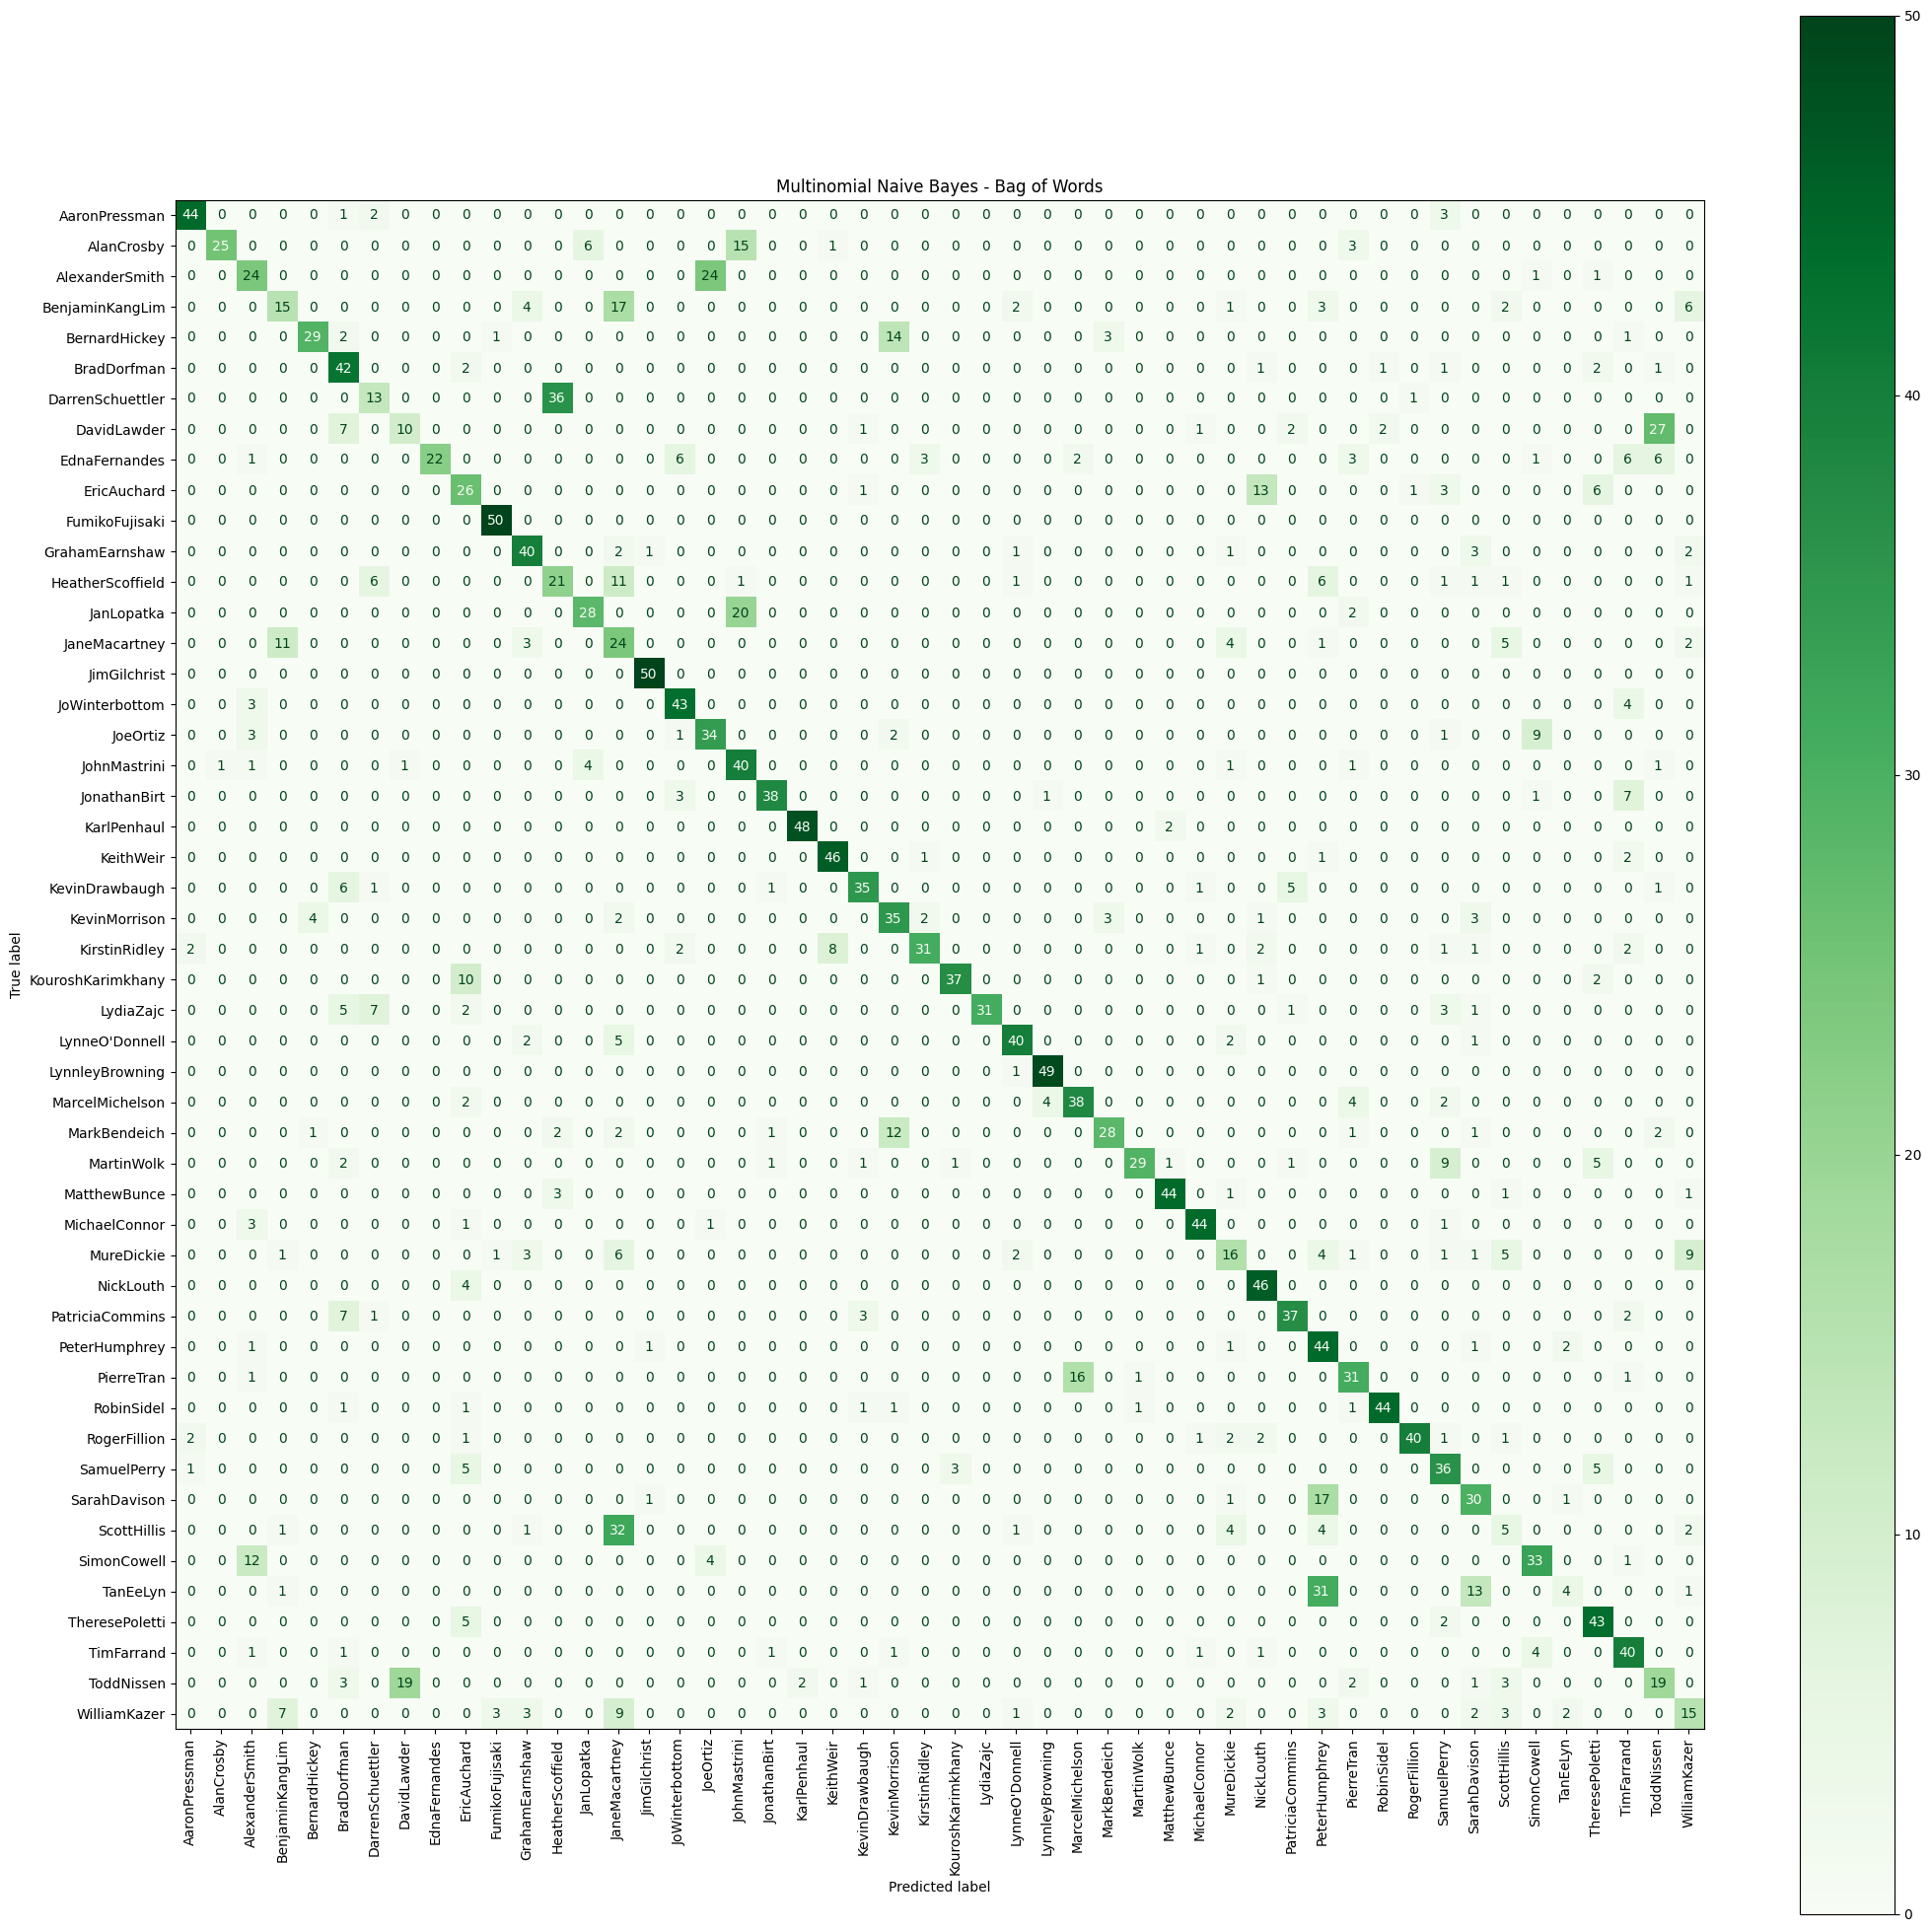

In [163]:
mnb_bow_cm = confusion_matrix(y_test, y_pred_mnb_bow)
fig, ax = plt.subplots(figsize=(25, 25))

ConfusionMatrixDisplay(
    confusion_matrix=mnb_bow_cm,
    display_labels=mnb_bow.classes_
).plot(ax=ax, cmap="Greens",xticks_rotation=90)

plt.title("Multinomial Naive Bayes - Bag of Words")
plt.show()

In [164]:
mnb_tfidf = MultinomialNB()

mnb_tfidf.fit(X_train_tfidf, y_train)

y_pred_mnb_tfidf = mnb_tfidf.predict(X_test_tfidf)

In [165]:
print("Naive Bayes - TF-IDF")
print("Accuracy :", accuracy_score(y_test, y_pred_mnb_tfidf))
print("Precision:", precision_score(y_test, y_pred_mnb_tfidf, average="weighted"))
print("Recall   :", recall_score(y_test, y_pred_mnb_tfidf, average="weighted"))
print("F1 Score :", f1_score(y_test, y_pred_mnb_tfidf, average="weighted"))

Naive Bayes - TF-IDF
Accuracy : 0.632
Precision: 0.6496080544084467
Recall   : 0.632
F1 Score : 0.6198535220874557


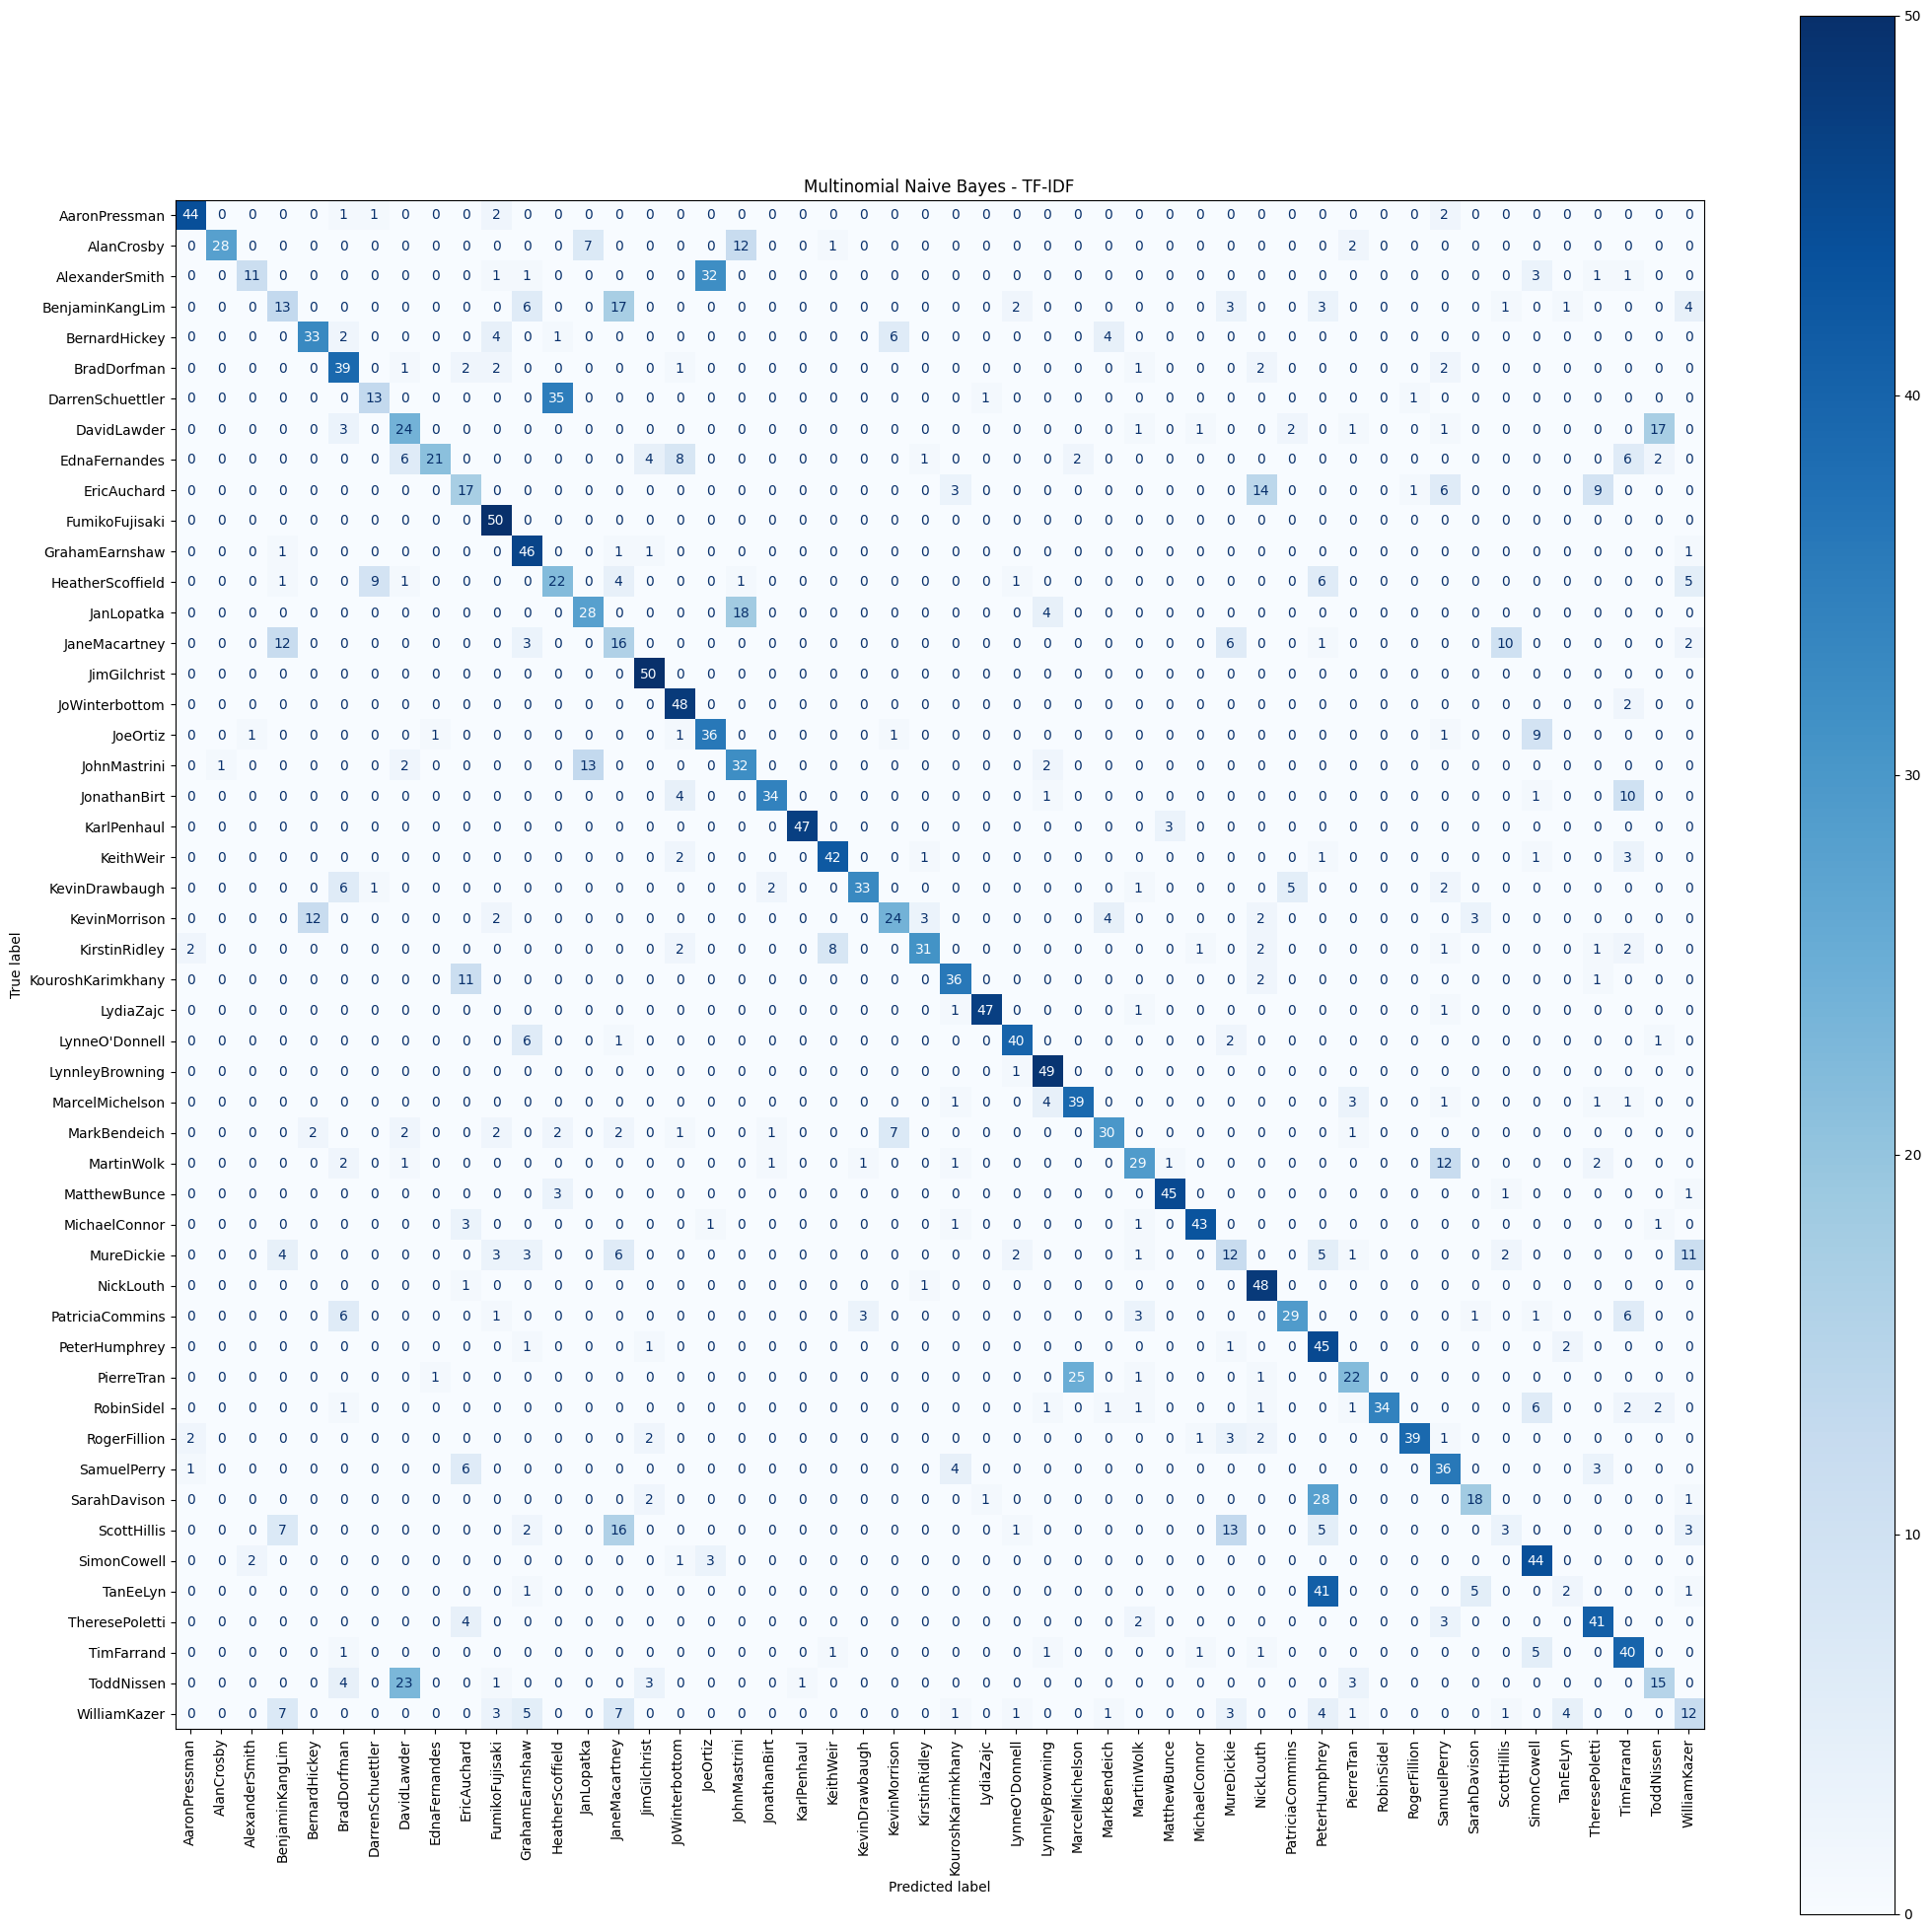

In [166]:
mnb_tfidf_cm = confusion_matrix(y_test, y_pred_mnb_tfidf)

fig, ax = plt.subplots(figsize=(25, 25))

ConfusionMatrixDisplay(
    confusion_matrix=mnb_tfidf_cm,
    display_labels=mnb_tfidf.classes_
).plot(ax=ax, cmap="Blues", xticks_rotation=90)

plt.title("Multinomial Naive Bayes - TF-IDF")
plt.show()

In [167]:
lr_bow = LogisticRegression(max_iter=1000)

lr_bow.fit(X_train_bow, y_train)

y_pred_lr_bow = lr_bow.predict(X_test_bow)

In [168]:
print("Logistic Regression - Bag of words")
print("Accuracy :", accuracy_score(y_test, y_pred_lr_bow))
print("Precision:", precision_score(y_test, y_pred_lr_bow, average="weighted"))
print("Recall   :", recall_score(y_test, y_pred_lr_bow, average="weighted"))
print("F1 Score :", f1_score(y_test, y_pred_lr_bow, average="weighted"))

Logistic Regression - Bag of words
Accuracy : 0.674
Precision: 0.6855635801422039
Recall   : 0.674
F1 Score : 0.6720250979452913


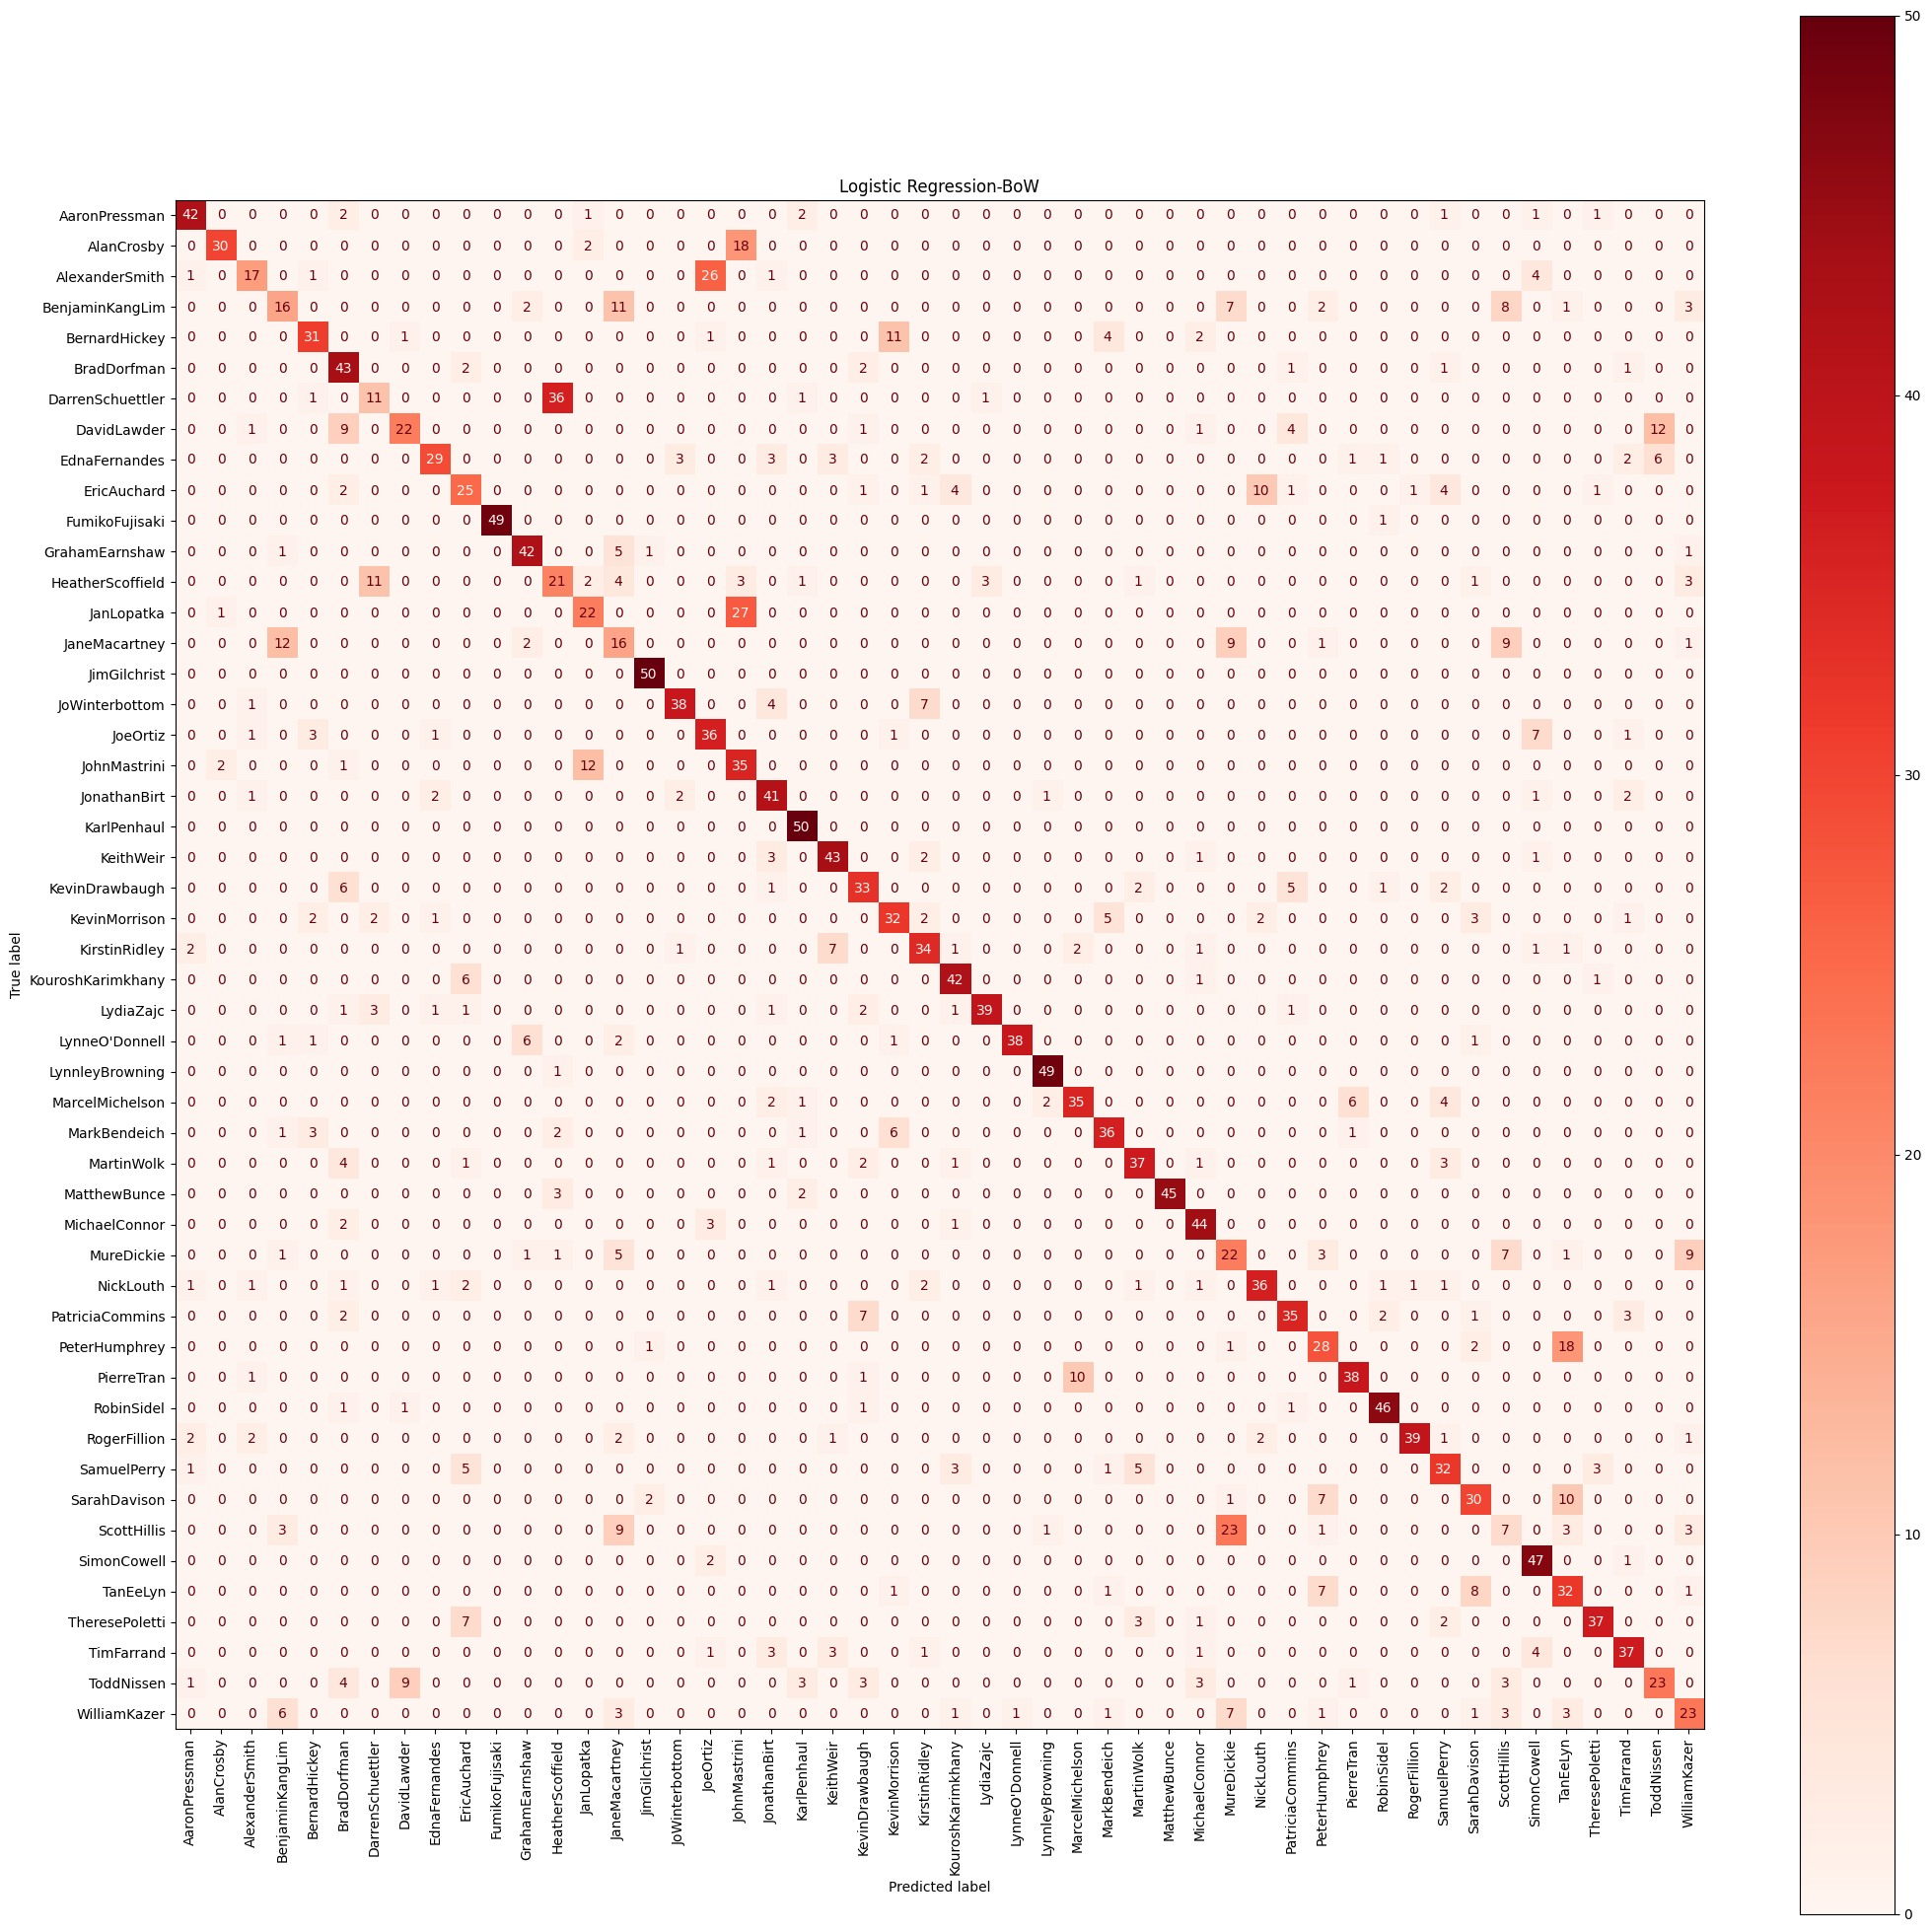

In [169]:
lr_bow_cm = confusion_matrix(y_test, y_pred_lr_bow)

fig, ax = plt.subplots(figsize=(25, 25))

ConfusionMatrixDisplay(
    confusion_matrix=lr_bow_cm,
    display_labels=lr_bow.classes_
).plot(ax=ax, cmap="Reds", xticks_rotation=90)

plt.title("Logistic Regression-BoW")
plt.show()

In [170]:
lr_tfidf = LogisticRegression(max_iter=1000)

lr_tfidf.fit(X_train_tfidf, y_train)

y_pred_lr_tfidf = lr_tfidf.predict(X_test_tfidf)

In [171]:
print("Logistic Regression - TF-IDF")
print("Accuracy :", accuracy_score(y_test, y_pred_lr_tfidf))
print("Precision:", precision_score(y_test, y_pred_lr_tfidf, average="weighted"))
print("Recall   :", recall_score(y_test, y_pred_lr_tfidf, average="weighted"))
print("F1 Score :", f1_score(y_test, y_pred_lr_tfidf, average="weighted"))

Logistic Regression - TF-IDF
Accuracy : 0.6424
Precision: 0.6558731505758978
Recall   : 0.6424
F1 Score : 0.6380288292221968


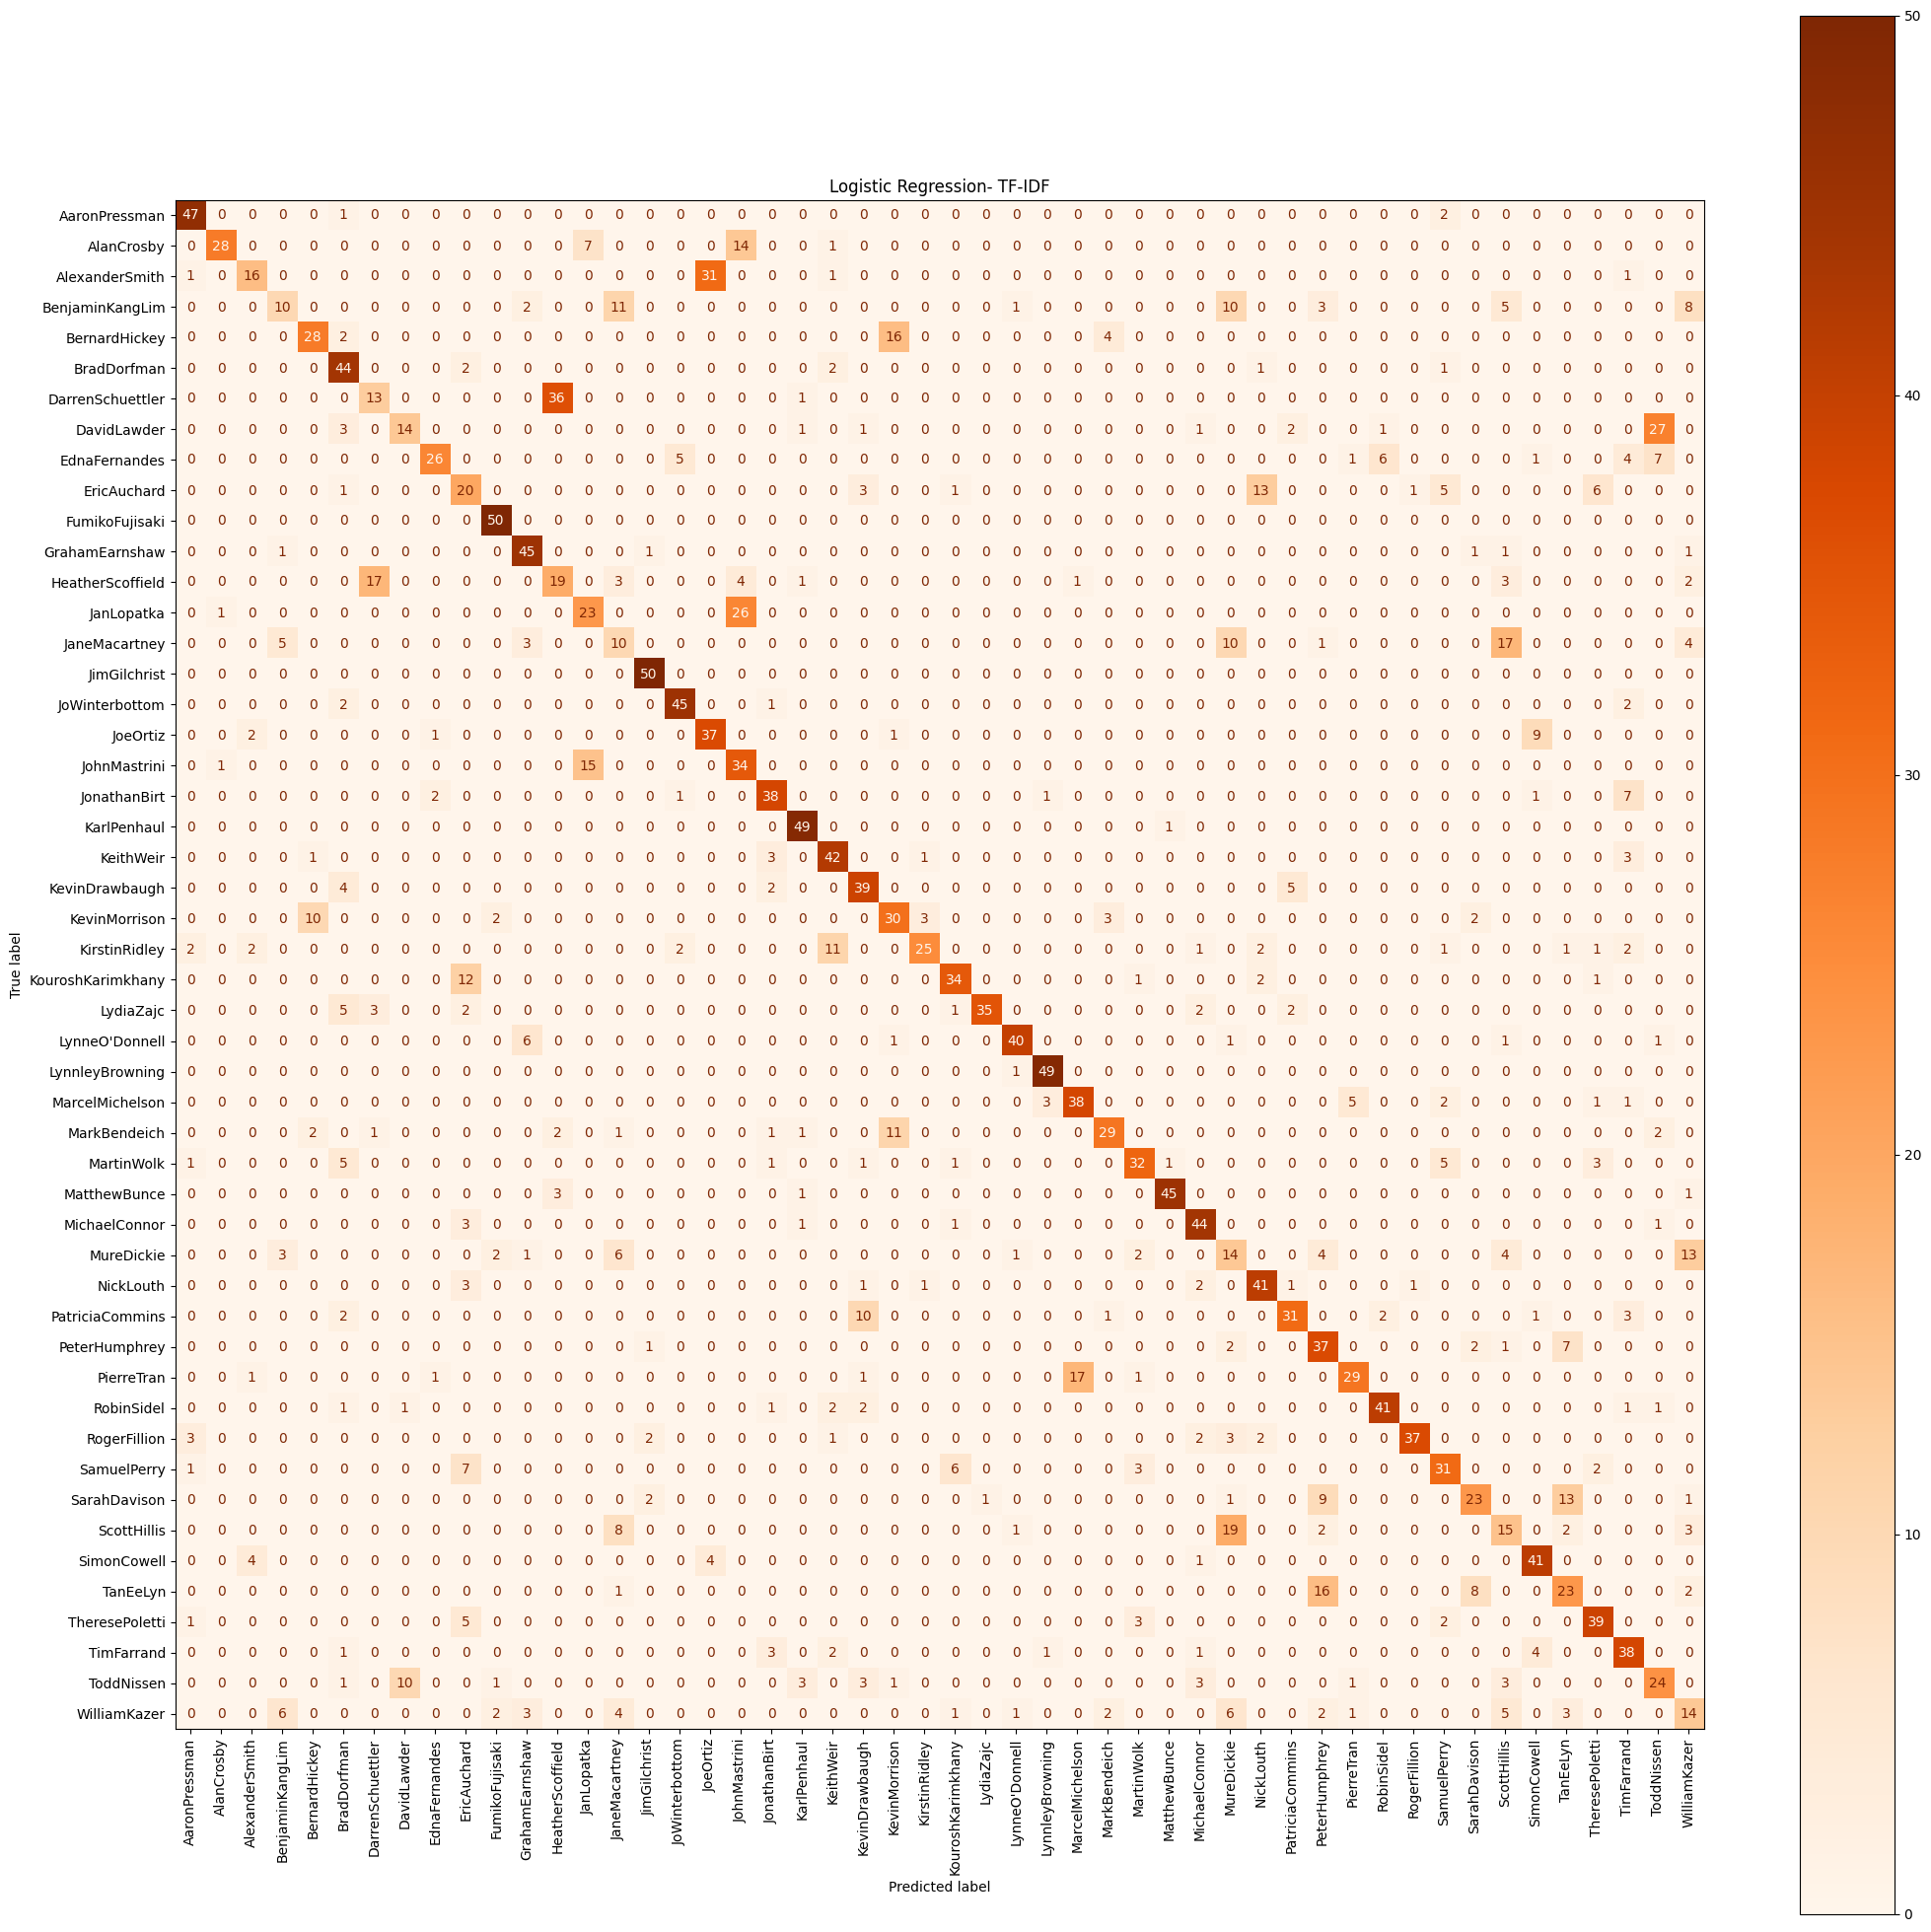

In [172]:
lr_tfidf_cm = confusion_matrix(y_test, y_pred_lr_tfidf)

fig, ax = plt.subplots(figsize=(25, 25))

ConfusionMatrixDisplay(
    confusion_matrix=lr_tfidf_cm,
    display_labels=lr_tfidf.classes_
).plot(ax=ax, cmap="Oranges", xticks_rotation=90)

plt.title("Logistic Regression- TF-IDF")
plt.show()

In [173]:
svm_bow = LinearSVC()

svm_bow.fit(X_train_bow, y_train)

y_pred_svm_bow = svm_bow.predict(X_test_bow)

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [174]:
print("Support Vector Machine - Bag of words")
print("Accuracy :", accuracy_score(y_test, y_pred_svm_bow))
print("Precision:", precision_score(y_test, y_pred_svm_bow, average="weighted"))
print("Recall   :", recall_score(y_test, y_pred_svm_bow, average="weighted"))
print("F1 Score :", f1_score(y_test, y_pred_svm_bow, average="weighted"))

Support Vector Machine - Bag of words
Accuracy : 0.6696
Precision: 0.6818718608765809
Recall   : 0.6696
F1 Score : 0.6669754785017751


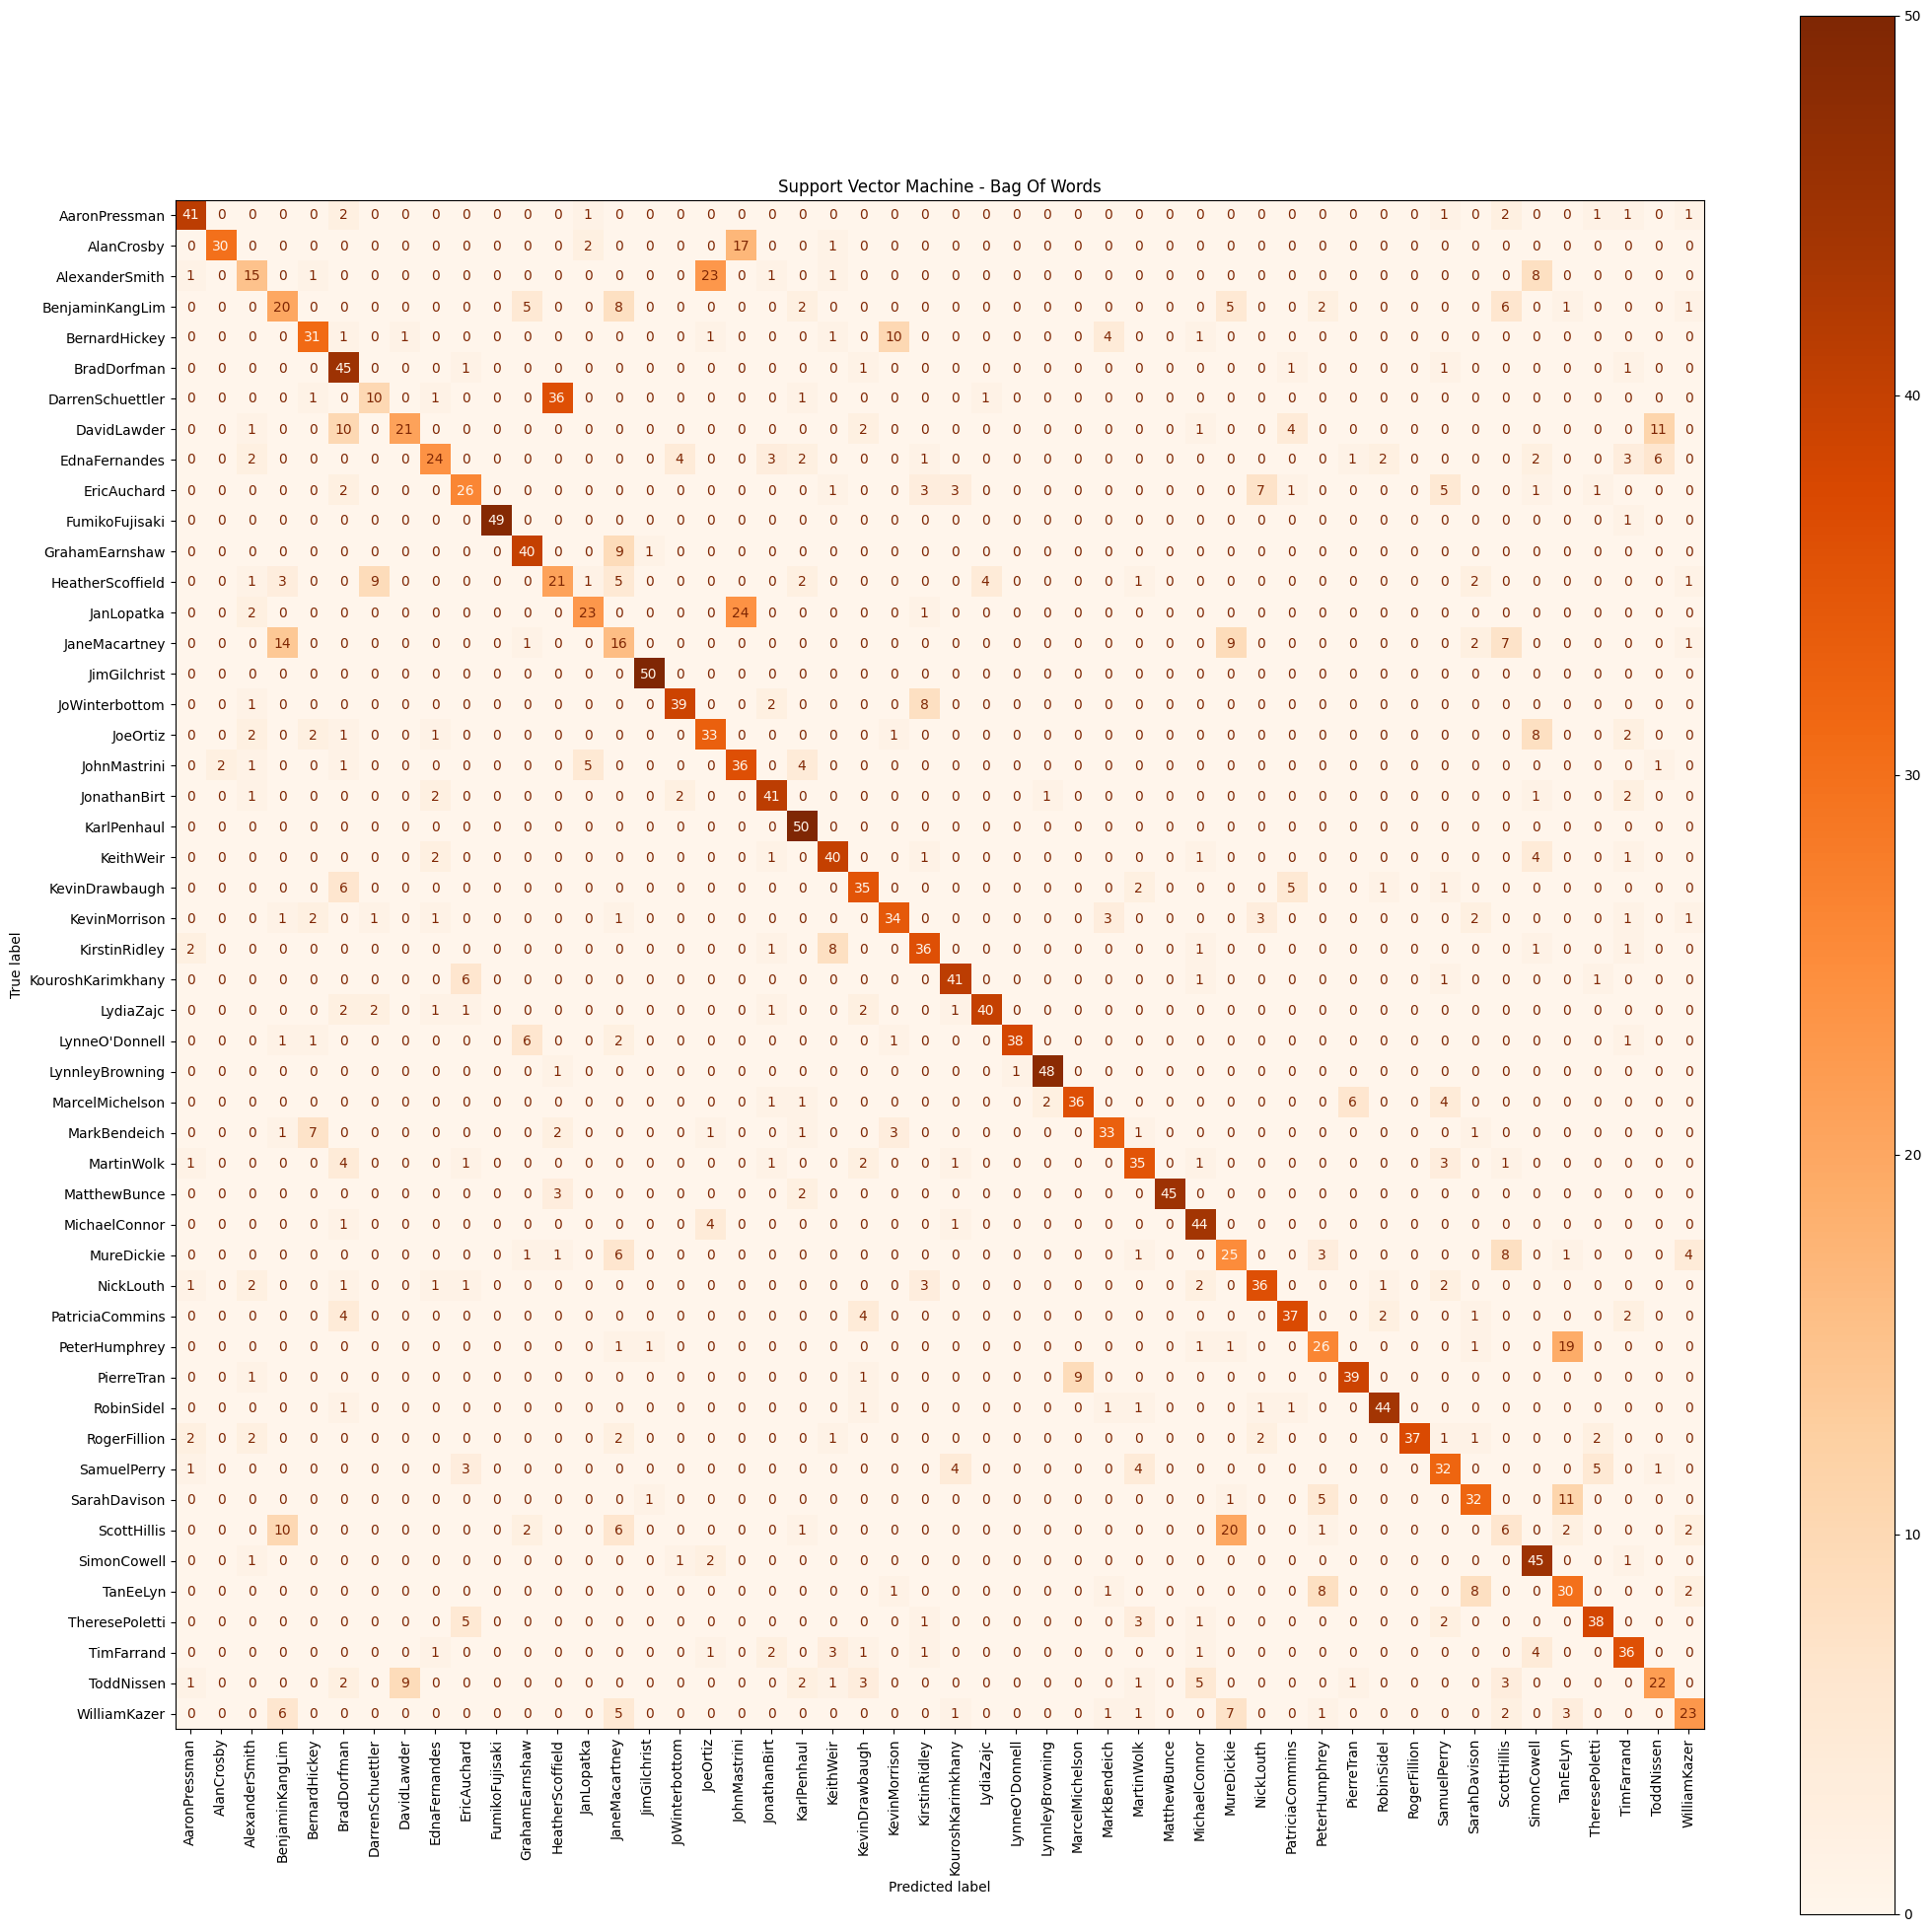

In [175]:
svm_bow_cm = confusion_matrix(y_test, y_pred_svm_bow)

fig, ax = plt.subplots(figsize=(25, 25))

ConfusionMatrixDisplay(
    confusion_matrix=svm_bow_cm,
    display_labels=svm_bow.classes_
).plot(ax=ax, cmap="Oranges", xticks_rotation=90)

plt.title("Support Vector Machine - Bag Of Words")
plt.show()

In [176]:
svm_tfidf = LinearSVC()

svm_tfidf.fit(X_train_tfidf, y_train)

y_pred_svm_tfidf = svm_tfidf.predict(X_test_tfidf)

In [177]:
print("Support Vector Machine - TF-IDF")
print("Accuracy :", accuracy_score(y_test, y_pred_svm_tfidf))
print("Precision:", precision_score(y_test, y_pred_svm_tfidf, average="weighted"))
print("Recall   :", recall_score(y_test, y_pred_svm_tfidf, average="weighted"))
print("F1 Score :", f1_score(y_test, y_pred_svm_tfidf, average="weighted"))

Support Vector Machine - TF-IDF
Accuracy : 0.6692
Precision: 0.6758593600269829
Recall   : 0.6692
F1 Score : 0.66490950544679


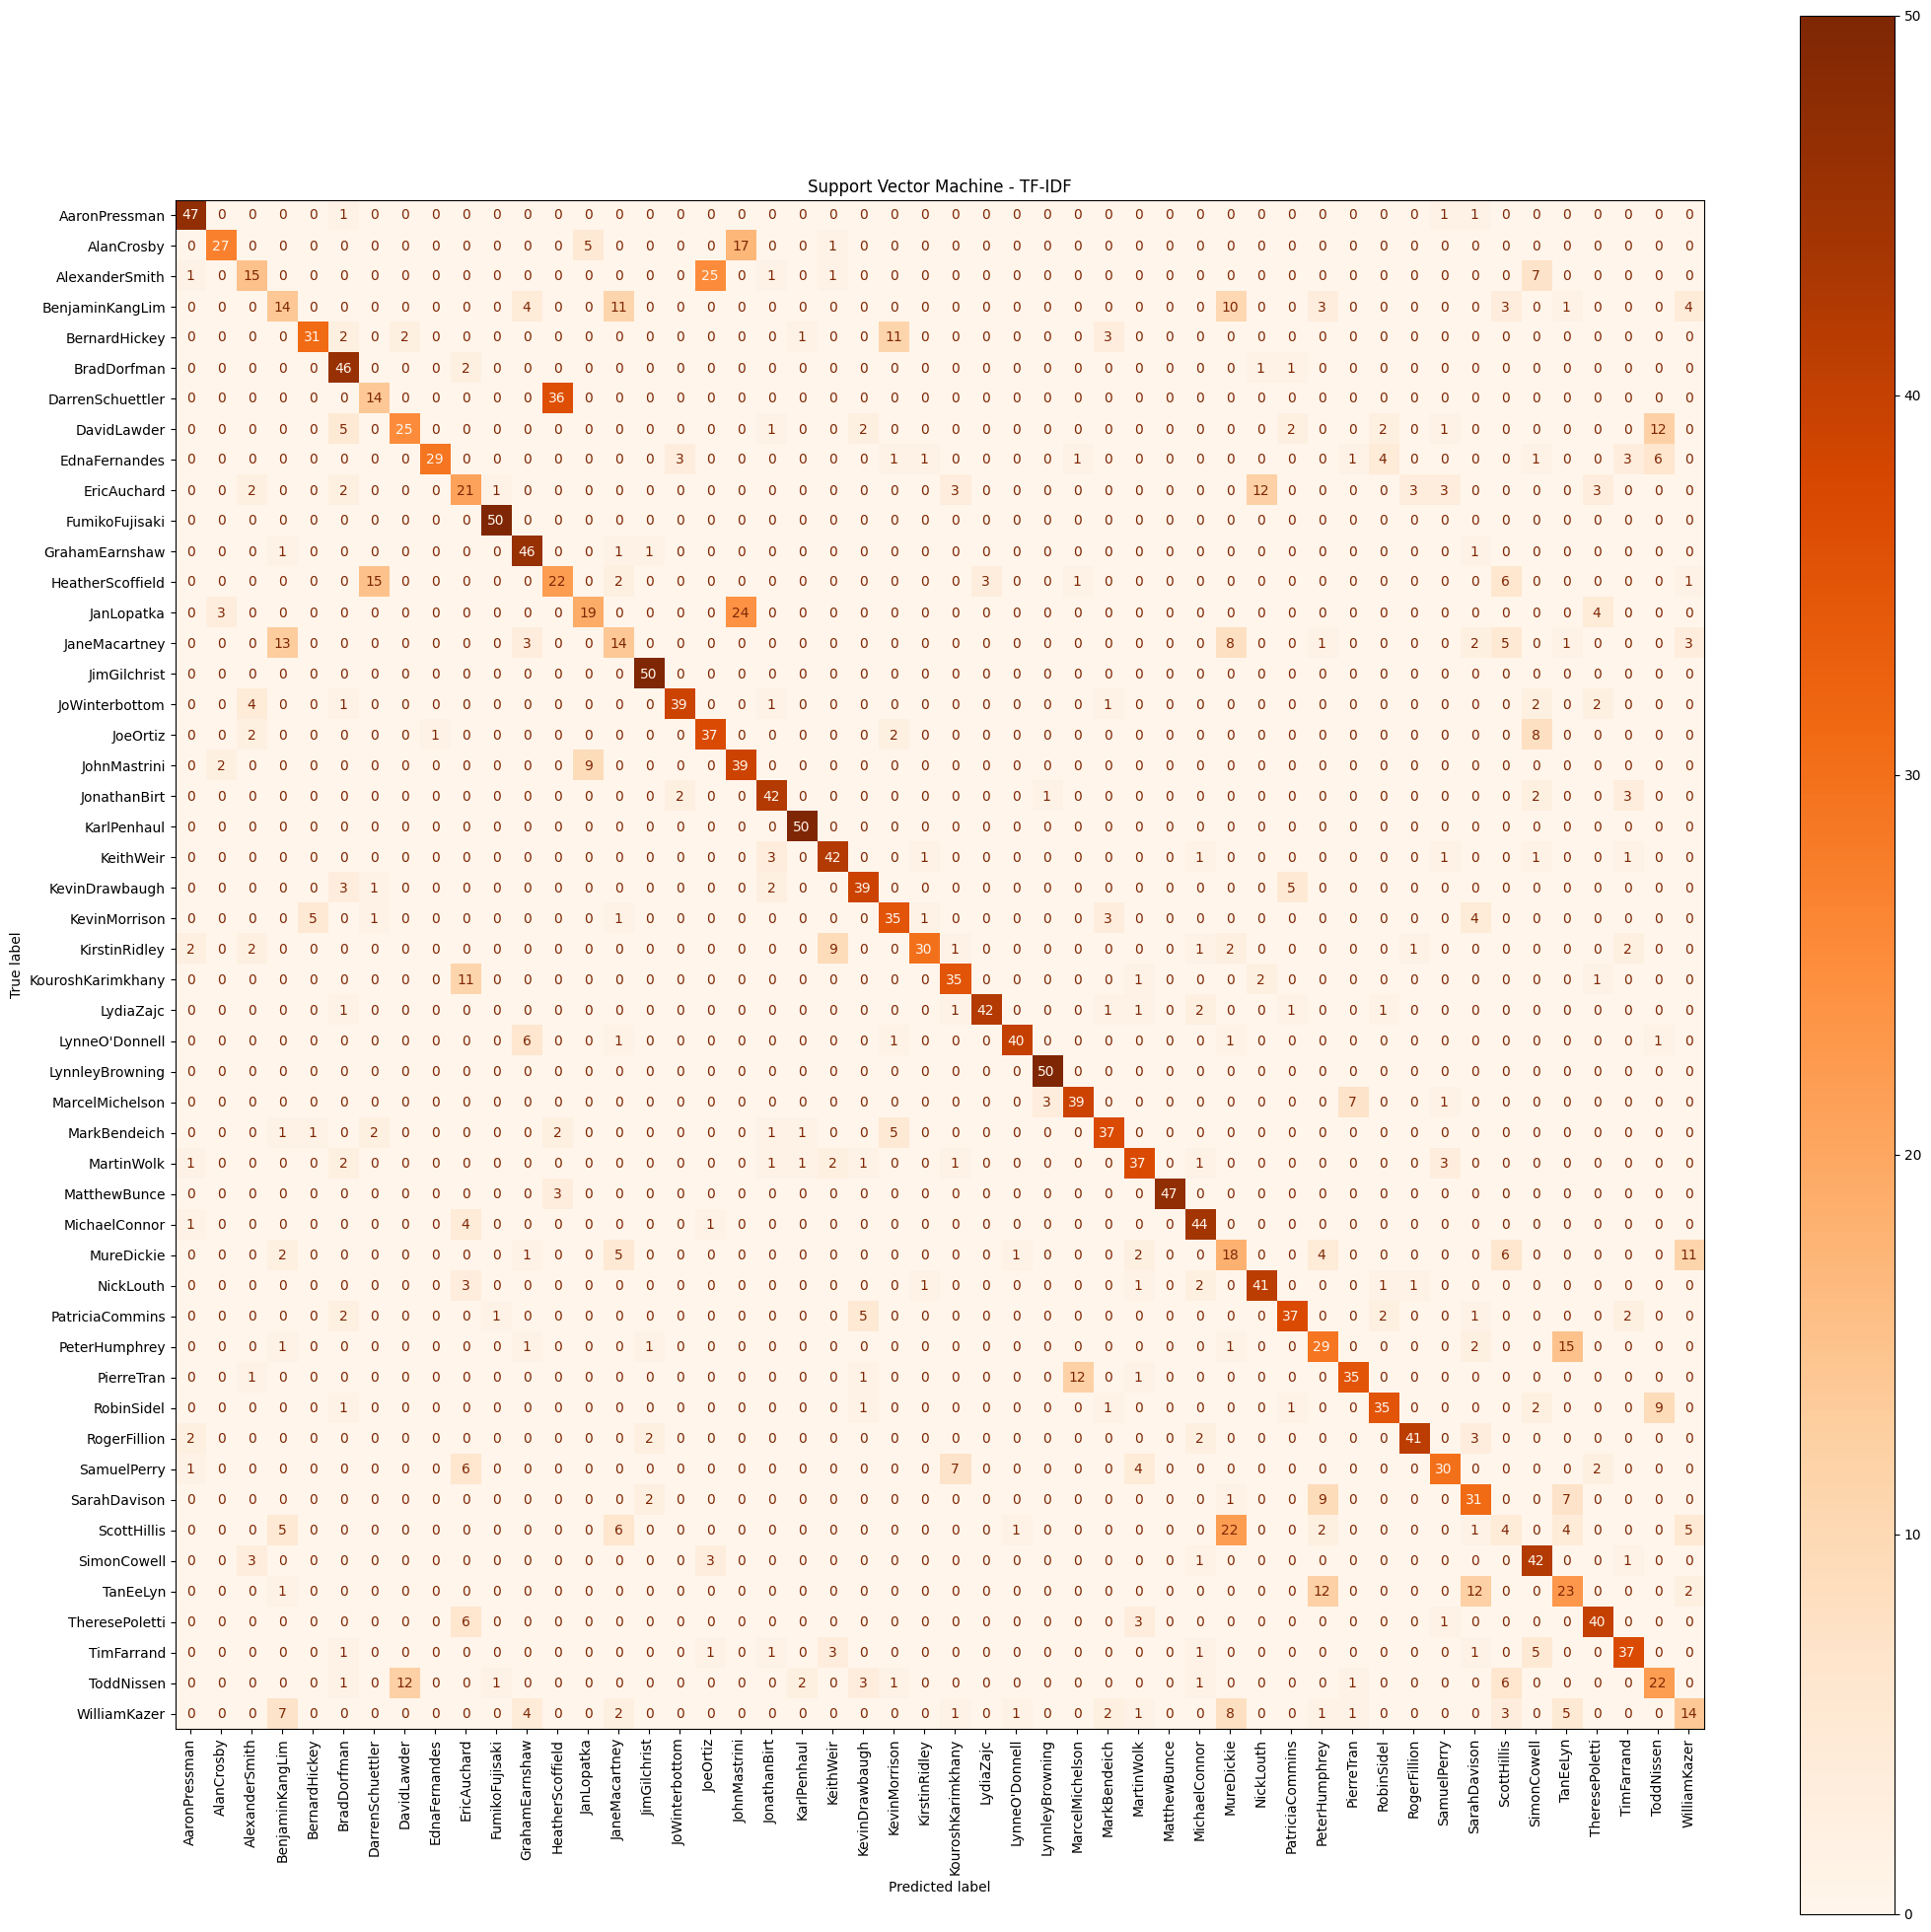

In [178]:
svm_tfidf_cm = confusion_matrix(y_test, y_pred_svm_tfidf)

fig, ax = plt.subplots(figsize=(25, 25))

ConfusionMatrixDisplay(
    confusion_matrix=svm_tfidf_cm,
    display_labels=svm_tfidf.classes_
).plot(ax=ax, cmap="Oranges", xticks_rotation=90)

plt.title("Support Vector Machine - TF-IDF")
plt.show()

In [179]:
df3 = pd.read_csv(Spooky_Aurthor_DIR)

train_data2, test_data2 = train_test_split(
    df3,
    test_size=0.2,
    random_state=42,
    stratify=df3["author"]
)

train_data2.dropna(how='any', inplace=True)
print(train_data2.head())

test_data2.dropna(how='any', inplace=True)
print(test_data2.head())


            id                                               text author
4330   id23740  I never sought to return to those tenebrous la...    HPL
18391  id16593  Among them the Greek army was encamped, and th...    MWS
12928  id09546  claws and teeth sharpened on centuries of corp...    HPL
4925   id21267  Goaded, by the interference, into a rage more ...    EAP
17281  id20831  The whole company, indeed, seemed now deeply t...    EAP
            id                                               text author
19375  id12024  So blended bank and shadow there That each see...    EAP
15714  id15178  I did only a retail business myself, but my ol...    EAP
15451  id18559  Old Waldron, who had curtailed his activities ...    HPL
7280   id21414  Let us refer, for example, to the last instanc...    EAP
6051   id25439  The first intelligence of the murder was broug...    EAP


In [180]:
train_data2["tokens"] = train_data2["text"].apply(word_tokenize)
print(train_data2[["text", "tokens"]].head())


test_data2["tokens"] = test_data2["text"].apply(word_tokenize)
print(test_data2[["text", "tokens"]].head())

                                                    text  \
4330   I never sought to return to those tenebrous la...   
18391  Among them the Greek army was encamped, and th...   
12928  claws and teeth sharpened on centuries of corp...   
4925   Goaded, by the interference, into a rage more ...   
17281  The whole company, indeed, seemed now deeply t...   

                                                  tokens  
4330   [I, never, sought, to, return, to, those, tene...  
18391  [Among, them, the, Greek, army, was, encamped,...  
12928  [claws, and, teeth, sharpened, on, centuries, ...  
4925   [Goaded, ,, by, the, interference, ,, into, a,...  
17281  [The, whole, company, ,, indeed, ,, seemed, no...  
                                                    text  \
19375  So blended bank and shadow there That each see...   
15714  I did only a retail business myself, but my ol...   
15451  Old Waldron, who had curtailed his activities ...   
7280   Let us refer, for example, to the last

In [181]:
train_data2["tokens"] = [
    [word_tokenized.lower() for word_tokenized in words]
    for words in train_data2["tokens"]
]
print(train_data2["tokens"].head())


test_data2["tokens"] = [
    [word_tokenized.lower() for word_tokenized in words]
    for words in test_data2["tokens"]
]
print(test_data2["tokens"].head())

4330     [i, never, sought, to, return, to, those, tene...
18391    [among, them, the, greek, army, was, encamped,...
12928    [claws, and, teeth, sharpened, on, centuries, ...
4925     [goaded, ,, by, the, interference, ,, into, a,...
17281    [the, whole, company, ,, indeed, ,, seemed, no...
Name: tokens, dtype: object
19375    [so, blended, bank, and, shadow, there, that, ...
15714    [i, did, only, a, retail, business, myself, ,,...
15451    [old, waldron, ,, who, had, curtailed, his, ac...
7280     [let, us, refer, ,, for, example, ,, to, the, ...
6051     [the, first, intelligence, of, the, murder, wa...
Name: tokens, dtype: object


In [182]:
train_data2["tokens"] = train_data2["tokens"].apply(
    lambda words: [token.lemma_ for token in nlp(" ".join(words))]
)

print(train_data2["tokens"].head())

test_data2["tokens"] = test_data2["tokens"].apply(
    lambda words: [token.lemma_ for token in nlp(" ".join(words))]
)

print(test_data2["tokens"].head())


4330     [I, never, seek, to, return, to, those, tenebr...
18391    [among, they, the, greek, army, be, encamp, ,,...
12928    [claws, and, tooth, sharpen, on, century, of, ...
4925     [goad, ,, by, the, interference, ,, into, a, r...
17281    [the, whole, company, ,, indeed, ,, seem, now,...
Name: tokens, dtype: object
19375    [so, blend, bank, and, shadow, there, that, ea...
15714    [I, do, only, a, retail, business, myself, ,, ...
15451    [old, waldron, ,, who, have, curtail, his, act...
7280     [let, we, refer, ,, for, example, ,, to, the, ...
6051     [the, first, intelligence, of, the, murder, be...
Name: tokens, dtype: object


In [183]:

train_data2["tokens"] = train_data2["tokens"].apply(
    lambda words: [word for word in words if word not in stop_words]
)

print(train_data2["tokens"].head())




test_data2["tokens"] = test_data2["tokens"].apply(
    lambda words: [word for word in words if word not in stop_words]
)

print(test_data1["tokens"].head())

4330     [I, never, seek, return, tenebrous, labyrinth,...
18391    [among, greek, army, encamp, ,, squadron, move...
12928     [claws, tooth, sharpen, century, corps, ., ., .]
4925     [goad, ,, interference, ,, rage, demoniacal, ,...
17281    [whole, company, ,, indeed, ,, seem, deeply, f...
Name: tokens, dtype: object
0    [u.s, lawmaker, redrafte, legislative, proposa...
1    [internet, new, product, come, go, blink, eye,...
2    [u.s, senator, tuesday, sharply, criticize, ne...
3    [senator, bob, kerrey, prepare, legislation, a...
4    [large, online, service, provider, react, caut...
Name: tokens, dtype: object


In [184]:
train_data2["tokens"] = train_data2["tokens"].apply(
    lambda words: [word for word in words if word not in string.punctuation]
)

print(train_data2["tokens"].head())

test_data2["tokens"] = test_data2["tokens"].apply(
    lambda words: [word for word in words if word not in string.punctuation]
)

print(test_data2["tokens"].head())

4330     [I, never, seek, return, tenebrous, labyrinth,...
18391    [among, greek, army, encamp, squadron, move, f...
12928              [claws, tooth, sharpen, century, corps]
4925     [goad, interference, rage, demoniacal, I, with...
17281    [whole, company, indeed, seem, deeply, feel, c...
Name: tokens, dtype: object
19375    [blend, bank, shadow, seem, pendulous, air, mi...
15714    [I, retail, business, old, habit, system, carr...
15451    [old, waldron, curtail, activity, would, make,...
7280     [let, refer, example, last, instance, one, com...
6051       [first, intelligence, murder, bring, g, person]
Name: tokens, dtype: object


In [185]:
train_data2["processed_text"] = train_data2["tokens"].apply(" ".join)

train_data2.head()




test_data2["processed_text"] = test_data2["tokens"].apply(" ".join)

test_data2.head()

,id,text,author,tokens,processed_text
19375,id12024,So blended bank and shadow there That each see...,EAP,"[blend, bank, shadow, seem, pendulous, air, mi...",blend bank shadow seem pendulous air mirror li...
15714,id15178,"I did only a retail business myself, but my ol...",EAP,"[I, retail, business, old, habit, system, carr...",I retail business old habit system carry I swi...
15451,id18559,"Old Waldron, who had curtailed his activities ...",HPL,"[old, waldron, curtail, activity, would, make,...",old waldron curtail activity would make take r...
7280,id21414,"Let us refer, for example, to the last instanc...",EAP,"[let, refer, example, last, instance, one, com...",let refer example last instance one combinatio...
6051,id25439,The first intelligence of the murder was broug...,EAP,"[first, intelligence, murder, bring, g, person]",first intelligence murder bring g person


In [186]:

bow = CountVectorizer()

X_train2_bow = bow.fit_transform(train_data2["processed_text"])
X_test2_bow = bow.transform(test_data2["processed_text"])

y_train2 = train_data2["author"]
y_test2 = test_data2["author"]

print(X_train2_bow.shape)
print(X_test2_bow.shape)


(15663, 17490)
(3916, 17490)


In [187]:

tfidf = TfidfVectorizer()

X_train2_tfidf = tfidf.fit_transform(train_data2["processed_text"])
X_test2_tfidf = tfidf.transform(test_data2["processed_text"])
print(X_train2_tfidf.shape)
print(X_test2_tfidf.shape)

(15663, 17490)
(3916, 17490)


In [188]:
mnb_bow = MultinomialNB()

mnb_bow.fit(X_train2_bow, y_train2)

y_pred2_mnb_bow = mnb_bow.predict(X_test2_bow)

In [189]:
print("Naive Bayes - Bag Of Words")
print("Accuracy :", accuracy_score(y_test2, y_pred2_mnb_bow))
print("Precision:", precision_score(y_test2, y_pred2_mnb_bow, average="weighted"))
print("Recall   :", recall_score(y_test2, y_pred2_mnb_bow, average="weighted"))
print("F1 Score :", f1_score(y_test2, y_pred2_mnb_bow, average="weighted"))

Naive Bayes - Bag Of Words
Accuracy : 0.8368232890704801
Precision: 0.8383722089642004
Recall   : 0.8368232890704801
F1 Score : 0.8370563567359768


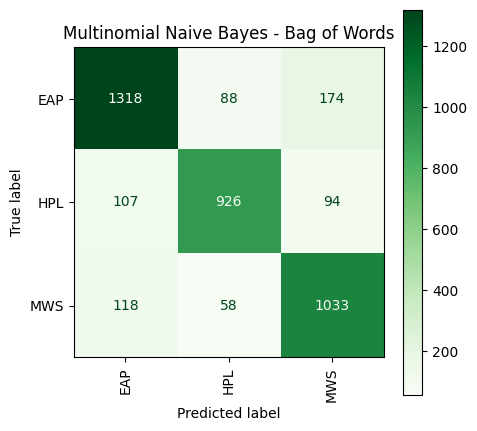

In [190]:
mnb_bow_cm2 = confusion_matrix(y_test2, y_pred2_mnb_bow)
fig, ax = plt.subplots(figsize=(5, 5))

ConfusionMatrixDisplay(
    confusion_matrix=mnb_bow_cm2,
    display_labels=mnb_bow.classes_
).plot(ax=ax, cmap="Greens", xticks_rotation=90)

plt.title("Multinomial Naive Bayes - Bag of Words")
plt.show()

In [191]:
mnb_tfidf = MultinomialNB()

mnb_tfidf.fit(X_train2_tfidf, y_train2)

y_pred2_mnb_tfidf = mnb_tfidf.predict(X_test2_tfidf)

In [192]:
print("Naive Bays - TF-IDF")
print("Accuracy :", accuracy_score(y_test2, y_pred2_mnb_tfidf))
print("Precision:", precision_score(y_test2, y_pred2_mnb_tfidf, average="weighted"))
print("Recall   :", recall_score(y_test2, y_pred2_mnb_tfidf, average="weighted"))
print("F1 Score :", f1_score(y_test2, y_pred2_mnb_tfidf, average="weighted"))

Naive Bays - TF-IDF
Accuracy : 0.8207354443309499
Precision: 0.8291203232692032
Recall   : 0.8207354443309499
F1 Score : 0.8200381993327259


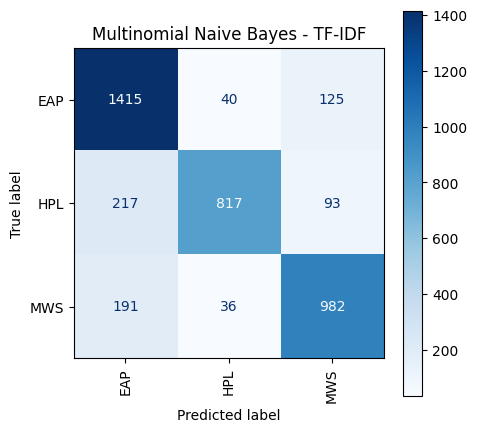

In [193]:
mnb_tfidf_cm = confusion_matrix(y_test2, y_pred2_mnb_tfidf)

fig, ax = plt.subplots(figsize=(5, 5))

ConfusionMatrixDisplay(
    confusion_matrix=mnb_tfidf_cm,
    display_labels=mnb_tfidf.classes_
).plot(ax=ax, cmap="Blues", xticks_rotation=90)

plt.title("Multinomial Naive Bayes - TF-IDF")
plt.show()

In [194]:
lr_bow = LogisticRegression(max_iter=1000)

lr_bow.fit(X_train2_bow, y_train2)

y_pred2_lr_bow = lr_bow.predict(X_test2_bow)

In [195]:
print("Logistic Regression - TF-IDF")
print("Accuracy :", accuracy_score(y_test2, y_pred2_lr_bow))
print("Precision:", precision_score(y_test2, y_pred2_lr_bow, average="weighted"))
print("Recall   :", recall_score(y_test2, y_pred2_lr_bow, average="weighted"))
print("F1 Score :", f1_score(y_test2, y_pred2_lr_bow, average="weighted"))

Logistic Regression - TF-IDF
Accuracy : 0.8110316649642493
Precision: 0.814015428404633
Recall   : 0.8110316649642493
F1 Score : 0.8107357654813354


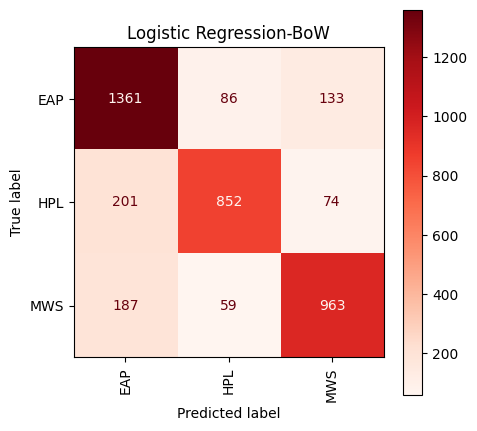

In [196]:
lr_bow_cm2 = confusion_matrix(y_test2, y_pred2_lr_bow)

fig, ax = plt.subplots(figsize=(5,5))

ConfusionMatrixDisplay(
    confusion_matrix=lr_bow_cm2,
    display_labels=lr_bow.classes_
).plot(ax=ax, cmap="Reds", xticks_rotation=90)

plt.title("Logistic Regression-BoW")
plt.show()

In [197]:
lr_tfidf = LogisticRegression(max_iter=1000)

lr_tfidf.fit(X_train2_tfidf, y_train2)

y_pred2_lr_tfidf = lr_tfidf.predict(X_test2_tfidf)

In [198]:
print("Logistic Regression - TF-IDF")
print("Accuracy :", accuracy_score(y_test2, y_pred2_lr_tfidf))
print("Precision:", precision_score(y_test2, y_pred2_lr_tfidf, average="weighted"))
print("Recall   :", recall_score(y_test2, y_pred2_lr_tfidf, average="weighted"))
print("F1 Score :", f1_score(y_test2, y_pred2_lr_tfidf, average="weighted"))

Logistic Regression - TF-IDF
Accuracy : 0.8169050051072523
Precision: 0.8199111789621856
Recall   : 0.8169050051072523
F1 Score : 0.8165829349212335


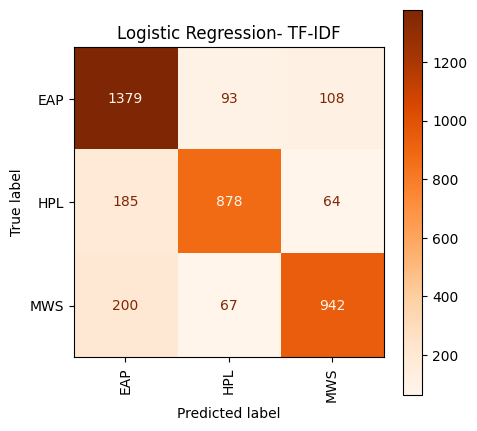

In [199]:
lr_tfidf_cm2 = confusion_matrix(y_test2, y_pred2_lr_tfidf)

fig, ax = plt.subplots(figsize=(5, 5))

ConfusionMatrixDisplay(
    confusion_matrix=lr_tfidf_cm2,
    display_labels=lr_tfidf.classes_
).plot(ax=ax, cmap="Oranges", xticks_rotation=90)

plt.title("Logistic Regression- TF-IDF")
plt.show()

In [200]:
svm_bow = LinearSVC()

svm_bow.fit(X_train2_bow, y_train2)

y_pred2_svm_bow = svm_bow.predict(X_test2_bow)

In [201]:
print("Support Vector Machine - Bag of Word")
print("Accuracy :", accuracy_score(y_test2, y_pred2_svm_bow))
print("Precision:", precision_score(y_test2, y_pred2_svm_bow, average="weighted"))
print("Recall   :", recall_score(y_test2, y_pred2_svm_bow, average="weighted"))
print("F1 Score :", f1_score(y_test2, y_pred2_svm_bow, average="weighted"))

Support Vector Machine - Bag of Word
Accuracy : 0.7985188968335035
Precision: 0.8009426238048026
Recall   : 0.7985188968335035
F1 Score : 0.798286949760524


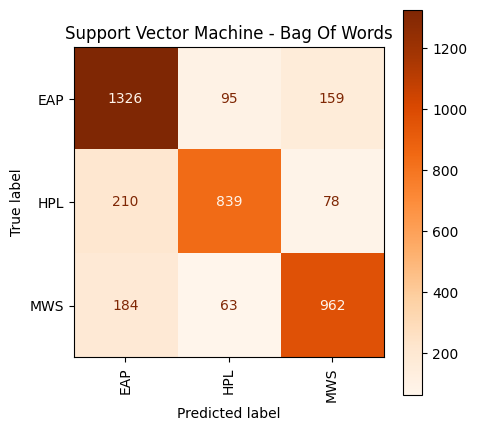

In [202]:
svm_bow_cm2 = confusion_matrix(y_test2, y_pred2_svm_bow)

fig, ax = plt.subplots(figsize=(5, 5))

ConfusionMatrixDisplay(
    confusion_matrix=svm_bow_cm2,
    display_labels=lr_tfidf.classes_
).plot(ax=ax, cmap="Oranges", xticks_rotation=90)

plt.title("Support Vector Machine - Bag Of Words")
plt.show()

In [203]:
svm_tfidf = LinearSVC()

svm_tfidf.fit(X_train2_tfidf, y_train2)

y_pred2_svm_tfidf = svm_tfidf.predict(X_test2_tfidf)

In [204]:
print("Accuracy :", accuracy_score(y_test2, y_pred2_svm_tfidf))
print("Precision:", precision_score(y_test2, y_pred2_svm_tfidf, average="weighted"))
print("Recall   :", recall_score(y_test2, y_pred2_svm_tfidf, average="weighted"))
print("F1 Score :", f1_score(y_test2, y_pred2_svm_tfidf, average="weighted"))

Accuracy : 0.8192032686414709
Precision: 0.8204366421418069
Recall   : 0.8192032686414709
F1 Score : 0.8191469177880787


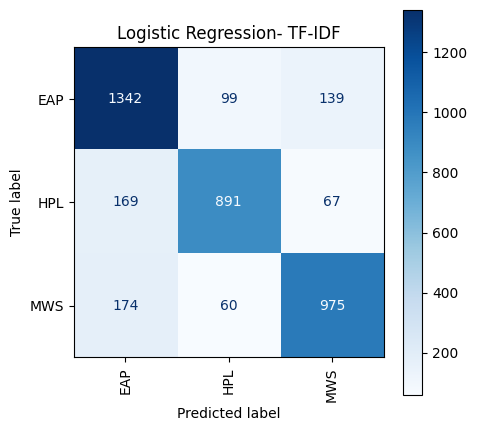

In [206]:
lr_tfidf_cm2 = confusion_matrix(y_test2, y_pred2_svm_tfidf)

fig, ax = plt.subplots(figsize=(5, 5))

ConfusionMatrixDisplay(
    confusion_matrix=lr_tfidf_cm2,
    display_labels=lr_tfidf.classes_
).plot(ax=ax, cmap="Blues", xticks_rotation=90)

plt.title("Logistic Regression- TF-IDF")
plt.show()